# Installing Pytorch and clone yolovnas

In [3]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://download.pytorch.org/whl/cu118
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 GB 575.6 kB/s eta 0:00:00:010m01:34
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 2.0 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 2.8 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 2.8 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.2/89.2 MB 2.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.0/154.0 KB 4.0 MB/s eta 0:00:00a 0:00:01
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [4]:
!git clone https://github.com/Deci-AI/super-gradients

Cloning into 'super-gradients'...
remote: Enumerating objects: 42235, done.
remote: Counting objects: 100% (3889/3889), done.
remote: Compressing objects: 100% (1315/1315), done.
remote: Total 42235 (delta 2543), reused 3371 (delta 2179), pack-reused 38346
Receiving objects: 100% (42235/42235), 305.41 MiB | 3.69 MiB/s, done.
Resolving deltas: 100% (28462/28462), done.


In [1]:
cd super-gradients

/home/muhammad.mehboob/super-gradients


In [3]:
!pip install protobuf==3.20.3

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 20.0 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: protobuf
    Found existing installation: protobuf 3.20.0
    Uninstalling protobuf-3.20.0:
      Successfully uninstalled protobuf-3.20.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorboard 2.10.1 requires protobuf<3.20,>=3.9.2, but you have protobuf 3.20.3 which is incompatible.

[notice] A new release of pip is available: 23.3.1 -> 24.0
[notice] To update, run: python3 -m pip install --upgrade pip


In [8]:
!pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable


# Load the model trained on COCO dataset

In [3]:
import torch
torch.cuda.empty_cache()
import super_gradients
from ultralytics import NAS
from ultralytics import YOLO
from super_gradients.training import models
from super_gradients.common.object_names import Models
from matplotlib import pyplot as plt
import numpy as np
import cv2

In [5]:
model = models.get(Models.YOLO_NAS_L, pretrained_weights="coco")

[2024-01-08 14:50:47] INFO - checkpoint_utils.py - License Notification: YOLO-NAS pre-trained weights are subjected to the specific license terms and conditions detailed in 
https://github.com/Deci-AI/super-gradients/blob/master/LICENSE.YOLONAS.md
By downloading the pre-trained weight files you agree to comply with these terms.
[2024-01-08 14:50:47] INFO - checkpoint_utils.py - Successfully loaded pretrained weights for architecture yolo_nas_l


In [16]:
model = model.to("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
model.predict_webcam()

In [17]:
IMAGES = [ "https://raw.githubusercontent.com/ultralytics/yolov5/master/data/images/bus.jpg",]

In [19]:
%matplotlib inline
predictions = model.predict(
    IMAGES,
)

/home/muhammad.mehboob/.local/lib/python3.10/site-packages/super_gradients/training/utils/media/image.py:64: UserWarning: It seems you are using predict() with batch input
  warnings.warn("It seems you are using predict() with batch input")
/home/muhammad.mehboob/.local/lib/python3.10/site-packages/numpy/lib/arraypad.py:487: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  x = np.array(x)
/home/muhammad.mehboob/.local/lib/python3.10/site-packages/torch/amp/autocast_mode.py:250: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn(
[2023-11-28 19:57:57] INFO - pipelines.py - Fusing some of the model's layers. If this takes too much memory, you can deactivate it by setting `fuse_model=False`


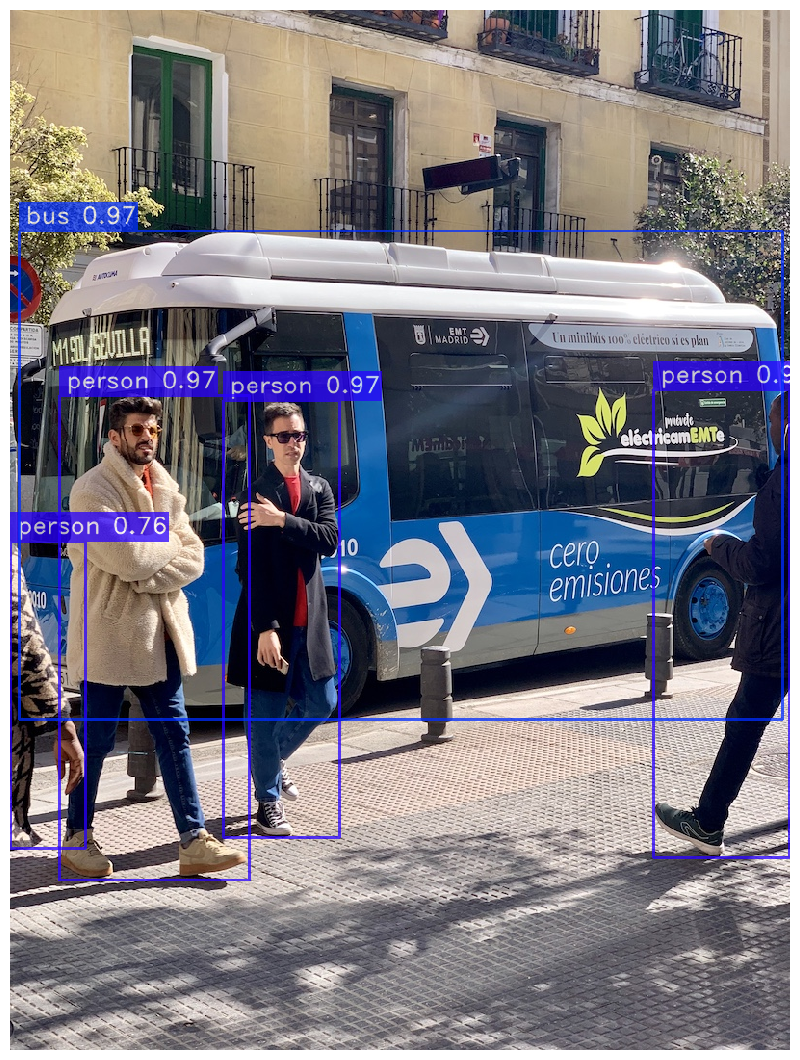

In [8]:
predictions.show()

# Import libraries

In [4]:
# Import opencv
import cv2 

# Import uuid
import uuid

# Import Operating System
import os

# Import time
import time

In [6]:
from super_gradients.training import Trainer
from super_gradients.training import dataloaders
from super_gradients.training.dataloaders.dataloaders import (
    coco_detection_yolo_format_train, 
    coco_detection_yolo_format_val
)
from super_gradients.training import models
from super_gradients.training.losses import PPYoloELoss
from super_gradients.training.metrics import (
    DetectionMetrics_050,
    DetectionMetrics_050_095
)
from super_gradients.training.models.detection_models.pp_yolo_e import PPYoloEPostPredictionCallback
from tqdm.auto import tqdm
 
import os
import requests
import zipfile
import cv2
import matplotlib.pyplot as plt
import glob
import numpy as np
import random
from PIL import Image 

# Dataset Path and Parameters 

In [7]:
ROOT_DIR = r'/home/muhammad.mehboob/super-gradients/images'
train_imgs_dir = r'/home/muhammad.mehboob/super-gradients/images/train/new0904'
train_labels_dir = r'/home/muhammad.mehboob/super-gradients/images/train/new0904ann'
val_imgs_dir =  r'/home/muhammad.mehboob/super-gradients/images/val/new0904'
val_labels_dir = r'/home/muhammad.mehboob/super-gradients/images/val/new0904ann'
test_imgs_dir = r'/home/muhammad.mehboob/super-gradients/images/test/images'
test_labels_dir = r'/home/muhammad.mehboob/super-gradients/images/test/annotations'
classes = ['Bits:PH1-M4-Phillips-Screws', 'Bits:PH2-Dia:3,9-4,5mm-Phillips-Screws','Bits:PH3-M6-Phillips-Screws' ,'Bits:PZ1-Dia:2,5-3mm-Pozidriv-Screws', 'Bits:PZ2-Dia:3,5-5mm-Pozidriv-Screws','Bits:PZ3-Dia:6mm-Pozidriv-Screws' ,'Bits-For-Plusminus-Screws-Slotted|Phillips', 'Bits-For-Plusminus-Screws-Slotted|Pozidriv',
           'Bits:TX10-Dia:3-3,5mm-TORX-Screws','Bits:TX20-Dia:4-4,5mm-TORX-Screws','Bits:TX25-Dia:5mm-TORX-Screws','Bits:TX30-Dia:6mm-TORX-Screws', 'Bits-For-TORX-BO-Screws',
           'Bits-For-TORX-Plus-Screws', 'Bits-For-TORX-Plus-IPR-Screws', 'Bits:Slotted 0,8-M3-Slotted-Screws', 'Bits:Slotted 1,0-M4-Slotted-Screws', 'Bits:Slotted 1,2-M5-Slotted-Screws',
           'Bits:HX2,5-For-Hexagon-Socket-Screws', 'Bits:HX3-For-Hexagon-Socket-Screws','Bits:HX4-For-Hexagon-Socket-Screws','Bits:HX5-For-Hexagon-Socket-Screws','Bits-For-Hexagon-Socket-BO-Screws',
           'Bits-For-Square-Socket-Screws', 'Bits-For-TORQ-Set-Screws', 'Bits-For-TRI-WING-Screws', 'Bits-For-MultiPoint-Screws',
           'Bits-For-Microstix-Screws', 'Bits-For-Spanner-Screws', 'Bits:TX15-TORX-Screws']

dataset_params = {
    'data_dir':ROOT_DIR,
    'train_images_dir':train_imgs_dir,
    'train_labels_dir':train_labels_dir,
    'val_images_dir':val_imgs_dir,
    'val_labels_dir':val_labels_dir,
    'test_images_dir':test_imgs_dir,
    'test_labels_dir':test_labels_dir,
    'classes':classes 
}

# global parameters


In [8]:
EPOCHS = 200
BATCH_SIZE =16
WORKERS = 8

# Dataset preparation

In [9]:
train_data = coco_detection_yolo_format_train(
    dataset_params={
        'data_dir': dataset_params['data_dir'],
        'images_dir': dataset_params['train_images_dir'],
        'labels_dir': dataset_params['train_labels_dir'],
        'classes': dataset_params['classes']
    },
    dataloader_params={
        'batch_size':BATCH_SIZE,
        'num_workers':WORKERS
    }
)
 
val_data = coco_detection_yolo_format_val(
    dataset_params={
        'data_dir': dataset_params['data_dir'],
        'images_dir': dataset_params['val_images_dir'],
        'labels_dir': dataset_params['val_labels_dir'],
        'classes': dataset_params['classes']
    },
    dataloader_params={
        'batch_size':BATCH_SIZE,
        'num_workers':WORKERS
    }
)
test_data = coco_detection_yolo_format_val(
    dataset_params={
        'data_dir': dataset_params['data_dir'],
        'images_dir': dataset_params['test_images_dir'],
        'labels_dir': dataset_params['test_labels_dir'],
        'classes': dataset_params['classes']
    },
     dataloader_params={
        'batch_size':BATCH_SIZE,
        'num_workers':WORKERS
    }
)

[2024-04-12 10:02:57] INFO - detection_dataset.py - Dataset Initialization in progress. `cache_annotations=True` causes the process to take longer due to full dataset indexing.
Indexing dataset annotations: 100%|███████████████████████████████████████████████████████████████████████████████████| 186/186 [00:00<00:00, 7699.69it/s]
[2024-04-12 10:02:57] INFO - detection_dataset.py - Dataset Initialization in progress. `cache_annotations=True` causes the process to take longer due to full dataset indexing.
Indexing dataset annotations: 100%|███████████████████████████████████████████████████████████████████████████████████| 186/186 [00:00<00:00, 7581.61it/s]
[2024-04-12 10:02:58] WARNING - yolo_format_detection.py - 60 images are note associated to any label file
[2024-04-12 10:02:58] WARNING - yolo_format_detection.py - As a consequence, 1/62 images and 1/1 label files will be used.
[2024-04-12 10:02:58] INFO - detection_dataset.py - Dataset Initialization in progress. `cache_annotations

In [10]:
train_data.dataset.transforms 

[DetectionMosaic('additional_samples_count': 3, 'non_empty_targets': False, 'prob': 1.0, 'input_dim': (640, 640), 'enable_mosaic': True, 'border_value': 114),
 DetectionRandomAffine('additional_samples_count': 0, 'non_empty_targets': False, 'degrees': 10.0, 'translate': 0.1, 'scale': [0.1, 2], 'shear': 2.0, 'target_size': (640, 640), 'enable': True, 'filter_box_candidates': True, 'wh_thr': 2, 'ar_thr': 20, 'area_thr': 0.1, 'border_value': 114),
 DetectionMixup('additional_samples_count': 1, 'non_empty_targets': True, 'input_dim': (640, 640), 'mixup_scale': [0.5, 1.5], 'prob': 1.0, 'enable_mixup': True, 'flip_prob': 0.5, 'border_value': 114),
 DetectionHSV('additional_samples_count': 0, 'non_empty_targets': False, 'prob': 1.0, 'hgain': 5, 'sgain': 30, 'vgain': 30, 'bgr_channels': (0, 1, 2), '_additional_channels_warned': False),
 DetectionHorizontalFlip('additional_samples_count': 0, 'non_empty_targets': False, 'prob': 0.5),
 DetectionPaddedRescale('additional_samples_count': 0, 'non_em

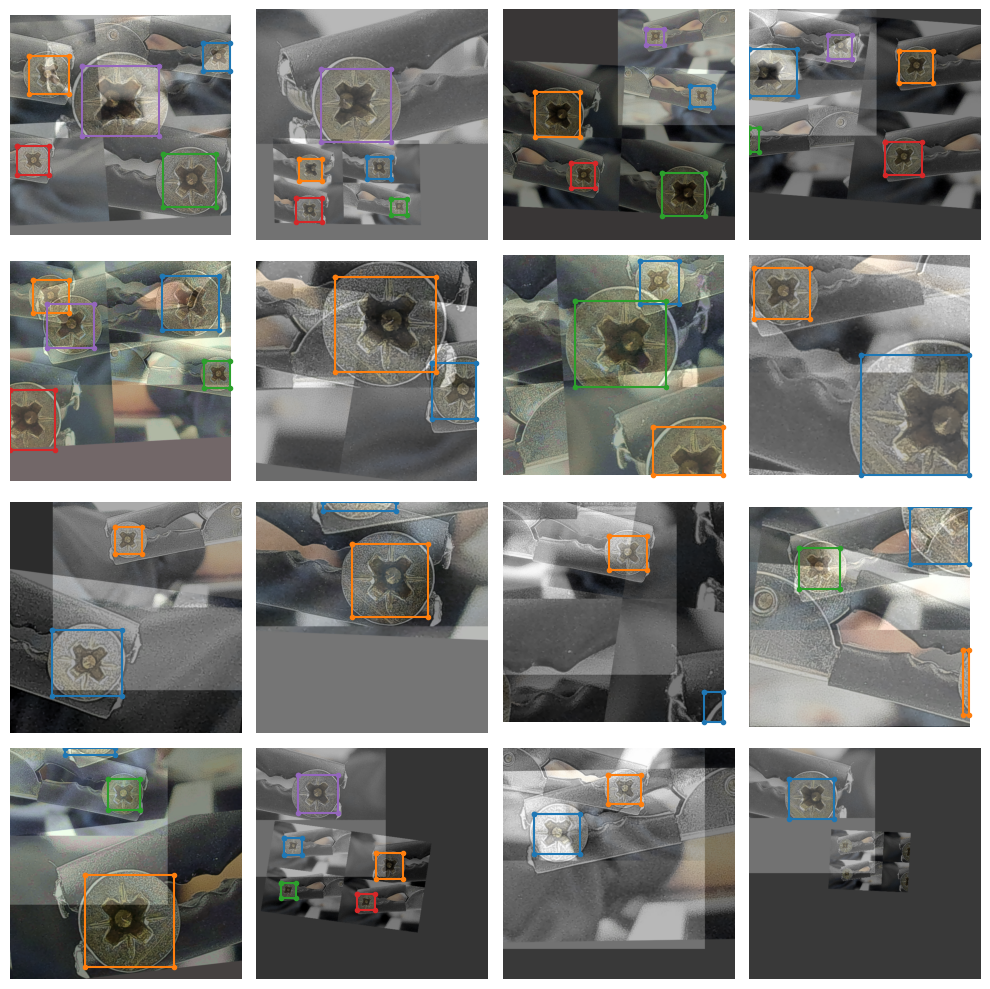

In [11]:
train_data.dataset.plot(plot_transformed_data=True)

# Training hyperparameters

In [12]:
train_params = {
    'silent_mode': False,
    "average_best_models":True,
    "warmup_mode": "linear_epoch_step",
    "warmup_initial_lr": 1e-6,
    "lr_warmup_epochs": 3,
    "initial_lr": 5e-4,
    "lr_mode": "cosine",
    "cosine_final_lr_ratio": 0.1,
    "optimizer": "Adam",
    "optimizer_params": {"weight_decay": 0.0001},
    "zero_weight_decay_on_bias_and_bn": True,
    "ema": True,
    "ema_params": {"decay": 0.9, "decay_type": "threshold"},
    "max_epochs": EPOCHS,
    "mixed_precision": True,
    "loss": PPYoloELoss(
        use_static_assigner=False,
        num_classes=len(dataset_params['classes']),
        reg_max=16
    ),
    "valid_metrics_list": [
        DetectionMetrics_050(
            score_thres=0.1,
            top_k_predictions=300,
            num_cls=len(dataset_params['classes']),
            normalize_targets=True,
            post_prediction_callback=PPYoloEPostPredictionCallback(
                score_threshold=0.01,
                nms_top_k=1000,
                max_predictions=300,
                nms_threshold=0.7
            )
        ),
        DetectionMetrics_050_095(
            score_thres=0.1,
            top_k_predictions=300,
            num_cls=len(dataset_params['classes']),
            normalize_targets=True,
            post_prediction_callback=PPYoloEPostPredictionCallback(
                score_threshold=0.01,
                nms_top_k=1000,
                max_predictions=300,
                nms_threshold=0.7
            )
        )
    ],
    "metric_to_watch": 'mAP@0.50:0.95'
}

# Training

In [10]:
CHECKPOINT_DIR = 'checkpoints'
trainer = Trainer(experiment_name= 'YOLO_NAS_L', ckpt_root_dir=CHECKPOINT_DIR)

In [14]:
model = models.get(Models.YOLO_NAS_L, pretrained_weights="coco", num_classes=30)

[2024-04-10 13:53:20] INFO - checkpoint_utils.py - License Notification: YOLO-NAS pre-trained weights are subjected to the specific license terms and conditions detailed in 
https://github.com/Deci-AI/super-gradients/blob/master/LICENSE.YOLONAS.md
By downloading the pre-trained weight files you agree to comply with these terms.
[2024-04-10 13:53:20] INFO - checkpoint_utils.py - Successfully loaded pretrained weights for architecture yolo_nas_l


In [ ]:
trainer.train(model=model, training_params=train_params, train_loader=train_data, valid_loader=val_data)

[2024-04-10 13:53:21] INFO - sg_trainer.py - Starting a new run with `run_id=RUN_20240410_135321_586615`
[2024-04-10 13:53:21] INFO - sg_trainer.py - Checkpoints directory: checkpoints/YOLO_NAS_L/RUN_20240410_135321_586615
[2024-04-10 13:53:21] INFO - sg_trainer.py - Using EMA with params {'decay': 0.9, 'decay_type': 'threshold'}
/home/muhammad.mehboob/.local/lib/python3.10/site-packages/super_gradients/common/registry/registry.py:72: DeprecationWarning: Object name `linear_epoch_step` is now deprecated. Please replace it with `LinearEpochLRWarmup`.
  warnings.warn(f"Object name `{name}` is now deprecated. Please replace it with `{deprecated_names[name]}`.", DeprecationWarning)
/home/muhammad.mehboob/.local/lib/python3.10/site-packages/super_gradients/training/sg_trainer/sg_trainer.py:1670: UserWarning: Mixed precision training is not supported on CPU. Disabling mixed precision. (i.e. `mixed_precision=False`)
  warnings.warn("Mixed precision training is not supported on CPU. Disabling 

The console stream is now moved to checkpoints/YOLO_NAS_L/RUN_20240410_135321_586615/console_Apr10_13_53_21.txt


[2024-04-10 13:53:25] INFO - sg_trainer_utils.py - TRAINING PARAMETERS:
    - Mode:                         Single GPU
    - Number of GPUs:               0          (1 available on the machine)
    - Full dataset size:            186        (len(train_set))
    - Batch size per GPU:           16         (batch_size)
    - Batch Accumulate:             1          (batch_accumulate)
    - Total batch size:             16         (num_gpus * batch_size)
    - Effective Batch size:         16         (num_gpus * batch_size * batch_accumulate)
    - Iterations per epoch:         11         (len(train_loader))
    - Gradient updates per epoch:   11         (len(train_loader) / batch_accumulate)

[2024-04-10 13:53:25] INFO - sg_trainer.py - Started training for 200 epochs (0/199)

Train epoch 0: 100%|██████████| 11/11 [01:54<00:00, 10.38s/it, PPYoloELoss/loss=4.04, PPYoloELoss/loss_cls=2.53, PPYoloELoss/loss_dfl=0.851, PPYoloELoss/l
Validating: 100%|██████████| 12/12 [00:29<00:00,  2.42s/it]

SUMMARY OF EPOCH 0
├── Train
│   ├── Ppyoloeloss/loss_cls = 2.5296
│   ├── Ppyoloeloss/loss_iou = 0.6561
│   ├── Ppyoloeloss/loss_dfl = 0.8511
│   └── Ppyoloeloss/loss = 4.0368
└── Validation
    ├── Ppyoloeloss/loss_cls = 2.4986
    ├── Ppyoloeloss/loss_iou = 0.6667
    ├── Ppyoloeloss/loss_dfl = 1.2045
    ├── Ppyoloeloss/loss = 4.3698
    ├── Precision@0.50 = 0.0
    ├── Recall@0.50 = 0.0
    ├── Map@0.50 = 0.0
    ├── F1@0.50 = 0.0
    ├── Precision@0.50:0.95 = 0.0
    ├── Recall@0.50:0.95 = 0.0
    ├── Map@0.50:0.95 = 0.0
    └── F1@0.50:0.95 = 0.0



Train epoch 1: 100%|██████████| 11/11 [01:58<00:00, 10.73s/it, PPYoloELoss/loss=2.19, PPYoloELoss/loss_cls=1.27, PPYoloELoss/loss_dfl=0.478, PPYoloELoss/l
Validating epoch 1: 100%|██████████| 12/12 [00:30<00:00,  2.52s/it]
[2024-04-10 13:58:23] INFO - base_sg_logger.py - Checkpoint saved in checkpoints/YOLO_NAS_L/RUN_20240410_135321_586615/ckpt_best.pth
[2024-04-10 13:58:23] INFO - sg_trainer.py - Best checkpoint overriden: validation mAP@0.50:0.95: 0.8023381233215332


...

Train epoch 63: 100%|██████████| 11/11 [01:58<00:00, 10.76s/it, PPYoloELoss/loss=1.15, PPYoloELoss/loss_cls=0.535, PPYoloELoss/loss_dfl=0.371, PPYoloELoss
Validating epoch 63: 100%|██████████| 12/12 [00:31<00:00,  2.59s/it]


SUMMARY OF EPOCH 63
├── Train
│   ├── Ppyoloeloss/loss_cls = 0.5348
│   │   ├── Epoch N-1      = 0.5287 (↗ 0.0061)
│   │   └── Best until now = 0.5166 (↗ 0.0182)
│   ├── Ppyoloeloss/loss_iou = 0.2432
│   │   ├── Epoch N-1      = 0.2443 (↘ -0.0011)
│   │   └── Best until now = 0.2254 (↗ 0.0177)
│   ├── Ppyoloeloss/loss_dfl = 0.3715
│   │   ├── Epoch N-1      = 0.3732 (↘ -0.0017)
│   │   └── Best until now = 0.3561 (↗ 0.0153)
│   └── Ppyoloeloss/loss = 1.1494
│       ├── Epoch N-1      = 1.1461 (↗ 0.0033)
│       └── Best until now = 1.1003 (↗ 0.0491)
└── Validation
    ├── Ppyoloeloss/loss_cls = 0.4462
    │   ├── Epoch N-1      = 0.4546 (↘ -0.0084)
    │   └── Best until now = 0.4546 (↘ -0.0084)
    ├── Ppyoloeloss/loss_iou = 0.1811
    │   ├── Epoch N-1      = 0.1875 (↘ -0.0063)
    │   └── Best until now = 0.1813 (↘ -1e-04)
    ├── Ppyoloeloss/loss_dfl = 0.3251
    │   ├── Epoch N-1      = 0.3311 (↘ -0.006)
    │   └── Best until now = 0.3263 (↘ -0.0012)
    ├── Ppyoloeloss/loss = 0.

Train epoch 64: 100%|██████████| 11/11 [02:01<00:00, 11.05s/it, PPYoloELoss/loss=1.16, PPYoloELoss/loss_cls=0.546, PPYoloELoss/loss_dfl=0.373, PPYoloELoss
Validating epoch 64: 100%|██████████| 12/12 [00:30<00:00,  2.58s/it]
[2024-04-10 16:47:13] INFO - base_sg_logger.py - Checkpoint saved in checkpoints/YOLO_NAS_L/RUN_20240410_135321_586615/ckpt_best.pth
[2024-04-10 16:47:13] INFO - sg_trainer.py - Best checkpoint overriden: validation mAP@0.50:0.95: 0.8880888819694519


SUMMARY OF EPOCH 64
├── Train
│   ├── Ppyoloeloss/loss_cls = 0.5457
│   │   ├── Epoch N-1      = 0.5348 (↗ 0.0109)
│   │   └── Best until now = 0.5166 (↗ 0.0291)
│   ├── Ppyoloeloss/loss_iou = 0.2422
│   │   ├── Epoch N-1      = 0.2432 (↘ -0.001)
│   │   └── Best until now = 0.2254 (↗ 0.0167)
│   ├── Ppyoloeloss/loss_dfl = 0.3734
│   │   ├── Epoch N-1      = 0.3715 (↗ 0.0019)
│   │   └── Best until now = 0.3561 (↗ 0.0173)
│   └── Ppyoloeloss/loss = 1.1612
│       ├── Epoch N-1      = 1.1494 (↗ 0.0118)
│       └── Best until now = 1.1003 (↗ 0.061)
└── Validation
    ├── Ppyoloeloss/loss_cls = 0.4483
    │   ├── Epoch N-1      = 0.4462 (↗ 0.0021)
    │   └── Best until now = 0.4462 (↗ 0.0021)
    ├── Ppyoloeloss/loss_iou = 0.175
    │   ├── Epoch N-1      = 0.1811 (↘ -0.0061)
    │   └── Best until now = 0.1811 (↘ -0.0061)
    ├── Ppyoloeloss/loss_dfl = 0.3217
    │   ├── Epoch N-1      = 0.3251 (↘ -0.0034)
    │   └── Best until now = 0.3251 (↘ -0.0034)
    ├── Ppyoloeloss/loss = 0.9451

Train epoch 65:  27%|██▋       | 3/11 [00:47<01:48, 13.61s/it, PPYoloELoss/loss=1.1, PPYoloELoss/loss_cls=0.513, PPYoloELoss/loss_dfl=0.358, PPYoloELoss/l

# Load the model

In [13]:
model = models.get('YOLO_NAS_L',
                        num_classes=30,
                        checkpoint_path='/home/muhammad.mehboob/super-gradients/checkpoints/YOLO_NAS_L/RUN_20240410_135321_586615/ckpt_best.pth')
                        

[2024-04-12 10:04:08] INFO - checkpoint_utils.py - Successfully loaded model weights from /home/muhammad.mehboob/super-gradients/checkpoints/YOLO_NAS_L/RUN_20240410_135321_586615/ckpt_best.pth EMA checkpoint.


In [87]:
pwd

'/home/muhammad.mehboob/super-gradients'

In [20]:
model = model.to("cuda" if torch.cuda.is_available() else "cpu")

# Test the images 

In [184]:
IMAGES = [ r"/home/muhammad.mehboob/super-gradients/images/test/images/new/WIN_20240412_10_52_14_Pro.jpg"]

In [185]:
%matplotlib inline
predictions = model.predict (IMAGES,)

[2024-04-12 12:03:37] INFO - pipelines.py - Fusing some of the model's layers. If this takes too much memory, you can deactivate it by setting `fuse_model=False`


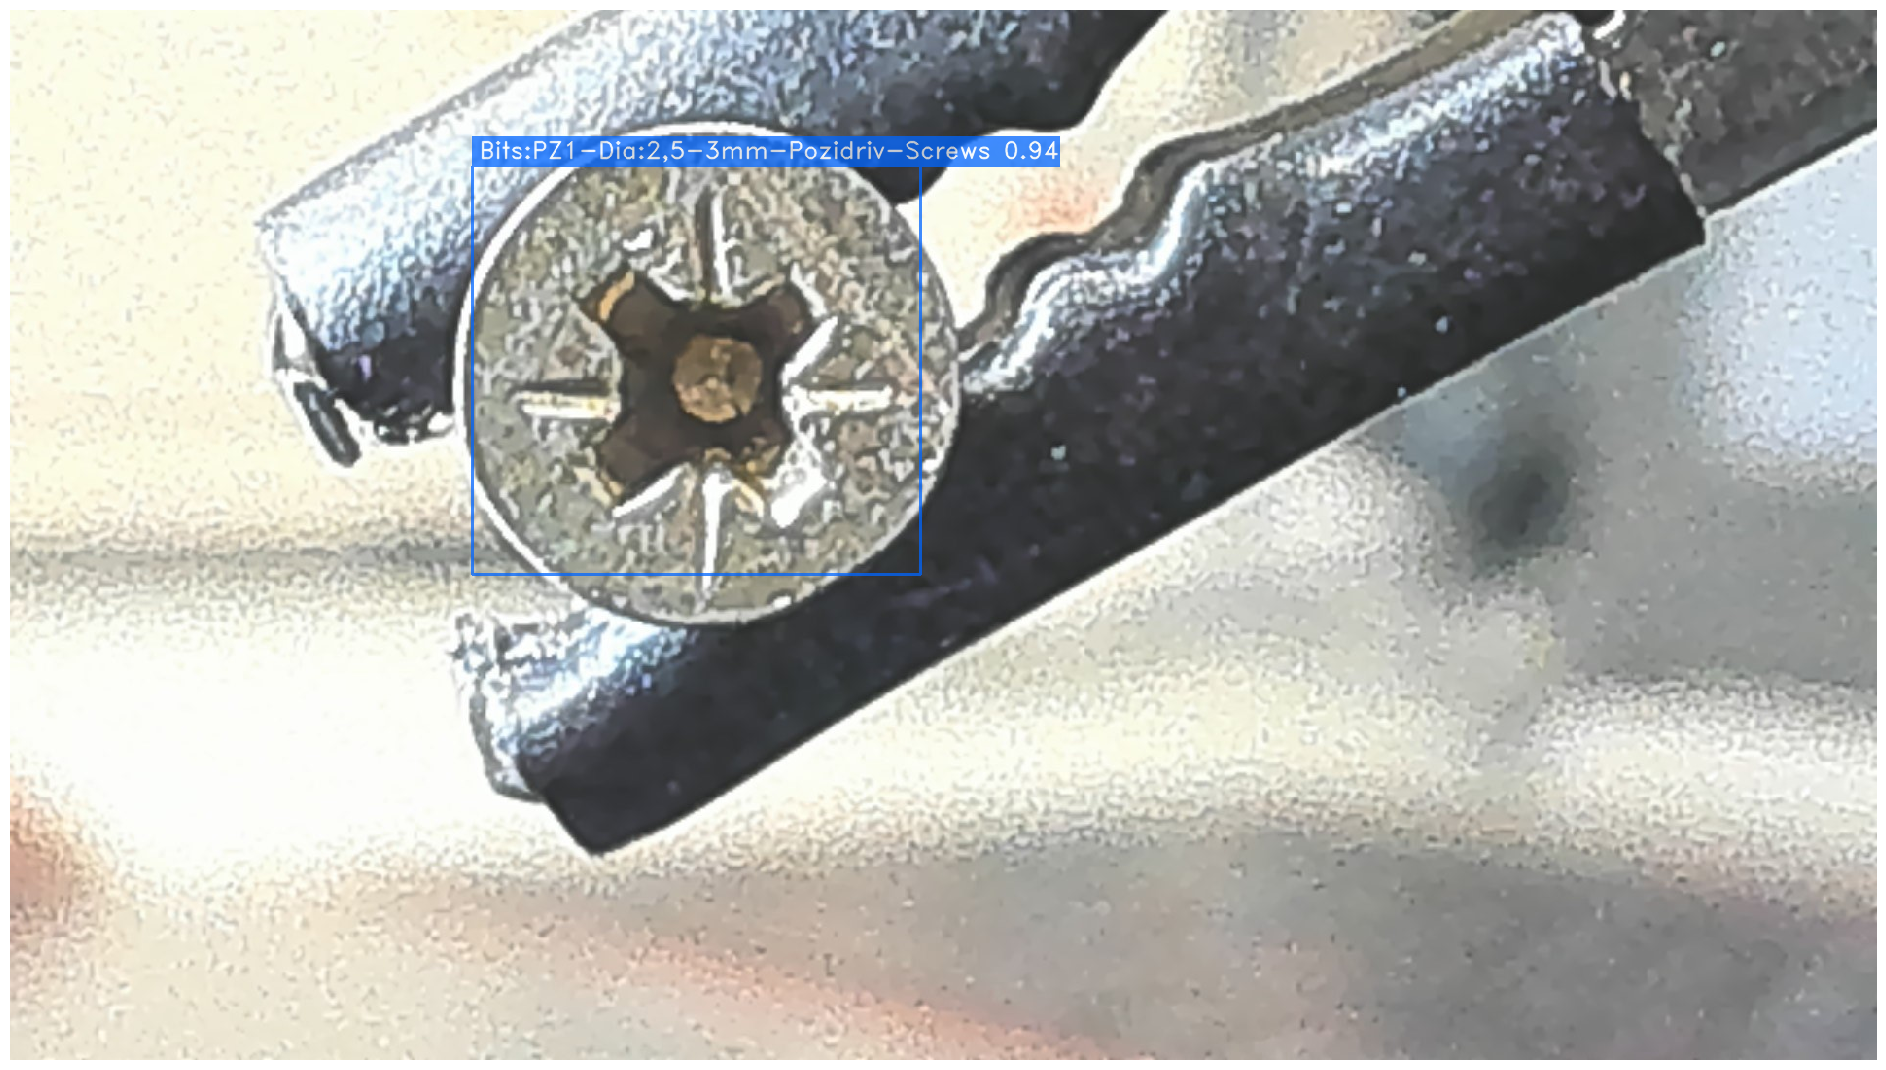

In [186]:
predictions.show()

In [187]:
predictions.save(r'/home/muhammad.mehboob/super-gradients/images/testimages/120')

# Live prediction 

In [ ]:
model.predict_webcam()

# Model Validation

In [16]:
trainer.test(model=model,
            test_loader=test_data,
            test_metrics_list=DetectionMetrics_050(score_thres=0.1, 
                                                   top_k_predictions=300, 
                                                   num_cls=2, 
                                                   normalize_targets=True, 
                                                   post_prediction_callback=PPYoloEPostPredictionCallback(score_threshold=0.01, 
                                                                                                          nms_top_k=1000, 
                                                                                                          max_predictions=300,                                                                              
                                                                                                          nms_threshold=0.7)))

Testing: 100%|██████████| 1/1 [00:01<00:00,  1.51s/it]

{'PPYoloELoss/loss_cls': 2.078178,
 'PPYoloELoss/loss_iou': 0.28038588,
 'PPYoloELoss/loss_dfl': 0.540551,
 'PPYoloELoss/loss': 2.8991148,
 'Precision@0.50': 0.0,
 'Recall@0.50': 0.0,
 'mAP@0.50': 1.0,
 'F1@0.50': 0.0}

Testing: 100%|██████████| 1/1 [00:01<00:00,  1.80s/it]
